In [1]:
import matplotlib.pyplot as plt
import numpy as np
import xarray
import pandas as pd
import h5py as h5
import glob

from diff_phase_estimator import get_drizzly_phiDPs
from nimrod_reader import read_nimrod_aggregated_odim_h5



## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly
## supported by the U.S. Department of Energy as part of the Atmospheric
## Radiation Measurement (ARM) Climate Research Facility, an Office of
## Science user facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119



In [2]:
file='/gws/ssde/j25a/ncas_radar/vol2/avocet/ukmo-nimrod/raw_h5_data_final/single-site/chenies/2019/20190830_polar_pl_radar05_aggregate.h5'

In [4]:
radar = read_nimrod_aggregated_odim_h5(file, 'lp','1100')

In [5]:
#files = glob.glob('/gws/ssde/j25a/ncas_radar/vol2/avocet/ukmo-nimrod/raw_h5_data_final/single-site/deanhill/2019/2019*')
files = glob.glob('/gws/ssde/j25a/ncas_radar/vol2/avocet/ukmo-nimrod/raw_h5_data_final/single-site/chenies/2019/2019*')

In [8]:
starter = np.array([np.nan])
counter = 0
for file in files[:]:
    try:
        radar = read_nimrod_aggregated_odim_h5(file, 'lp','1050')
    except KeyError:
        pass
    phiDP = get_drizzly_phiDPs(radar, 10000,30000)
    if counter ==0:
        master_phiDP = np.concatenate((starter, phiDP.flatten()))
    else:
        master_phiDP = np.concatenate((master_phiDP, phiDP.flatten()))

    counter +=1

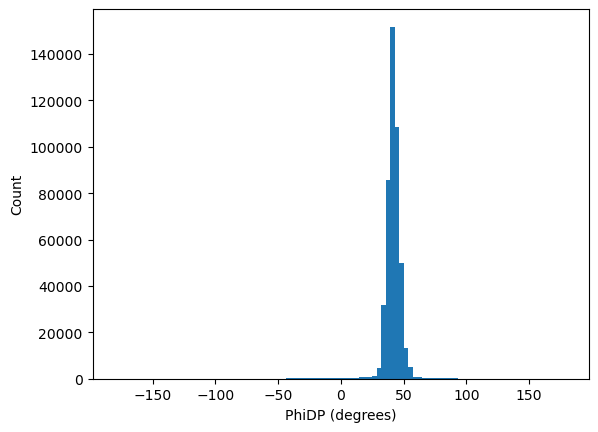

In [9]:
len(master_phiDP)
plt.hist(master_phiDP, bins = 100)
plt.xlabel('PhiDP (degrees)')
plt.ylabel('Count')
plt.grid()
plt.gcf().savefig('plots/Chenies 2019 1050am')
plt.show()

In [11]:
len(master_phiDP)

4467601